# Caption here


In [1]:
import gc
import geopandas as gpd
import numpy as np
import scanpy as sc
import squidpy as sq
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Importing the embeddings for both modalities

#### Variables, Files, Paths
##### Variables 
- `sample`: String. Defines the sample we are working from. E.g.: Colorectal_Cancer_Person_2 (CRC_P2)
- `bin_size`: String. Choose between 2um, 8um and 16um for Visium Outputs. Not necessary for Xenium - _select default somehow_?
- `xpca_hist`: Bool. Has PCA been performed on histology embeddings yet?
- `xpca_trans`: Bool. Has PCA been performed on transcriptomics embeddings yet?
- `xpca_col_hist`: String. Column that stores PCA embeddings for histology
- `xpca_col_trans`: String. Column that stores PCA embeddings for transcriptomics
- `loss_fct`: String. Loss function to apply to autoencoders 

##### Paths
- `basedir`: String. Base directory where all data is stored
- `dir_histology`: String. Directory where all histological information is stored. Can be per person or for all people combined (in this case: "combined" folder)
- `dir_transcriptomics`: String. Directory where all transcriptomics information is stored. Can be per person or for all people combined (in this case: "combined" folder)
- `dir_output`: String. Output directory autoencoder results.

##### Files and filenames
- `f_hist_adata`: h5ad. Contains histology information such as Slide_ID (=sample), column per patch with ID and embeddings, x any coord, gene counts, PCA, etc
- `f_trans_adata`: h5ad. Contains transcriptomics information such as Slide_ID (=sample), column per bin or cell with ID and embeddings, assigned Patch ID, genes, etc.
- `f_trans_coord`: parquet. For each cell/nucleus stores: ID, geomtetry, centroid, inner centroid, etc.

In [2]:
# Variables
sample = "CRC_P2"
bin_size = "002um"
dir_cellseg = "cell_seg_stardist" # in case of multiple cell segmentation methods, this determines which method we work with
xpca_hist = False    # checks if PCA has been performed yet
xpca_trans = False    # checks if PCA has been performed yet
xpca_col_hist = "X_pca"   # choose different name if PCA are stored under a different column name 
xpca_col_trans = "X_pca"   # choose different name if PCA are stored under a different column name 
loss_fct = "ntxent" # optional loss functions: ntxent, cosine


# Paths/Directories
basedir = Path("../../data")
dir_histology = basedir / "combined/01_preprocessing/unimodel/metadata"                               # Note: these directories refer to the combined folder. 
dir_transcriptomics = basedir / "combined/01_preprocessing" / dir_cellseg / bin_size / "custom_binning" # If you want to access a single slide folder, please define an extra path. 
dir_output = basedir / sample / "03_integration/autoencoders" / bin_size
dir_output.mkdir(parents=True, exist_ok=True)

# Files and filenames
f_hist_adata = sc.read_h5ad(dir_histology / "filtered_WSI_patch_embeddings.h5ad")
f_trans_adata = sc.read_h5ad(dir_transcriptomics / "patch_assigned_count_area_filtered_adata.h5ad")
f_trans_coord = gpd.read_parquet(dir_transcriptomics / "nuclei_geometry.parquet")

## Filter adata for single sample
f_hist_adata = f_hist_adata[f_hist_adata.obs["Slide_ID"] == sample]
f_trans_adata = f_trans_adata[f_trans_adata.obs["Slide_ID"] == sample]
f_trans_coord = f_trans_coord[f_trans_coord["Slide_ID"] == sample]

# Re-set indices
# Do not run this section(s) if 
#   1. f_trans_adata.index is already equal to the actual cell id and/or
#   2. f_hist_adata.index is already equal to the Patch_ID
if not f_trans_adata.obs["id"].is_unique:   # 1.
    raise ValueError(f"Cannot set 'id' as index: contains duplicates")
f_trans_adata.obs = f_trans_adata.obs.set_index(f_trans_adata.obs["id"].astype(str))

if not f_hist_adata.obs["Patch_ID"].is_unique:   # 2.
    raise ValueError(f"Cannot set 'Patch_ID' as index: contains duplicates")
f_hist_adata.obs = f_hist_adata.obs.set_index(f_hist_adata.obs["Patch_ID"].astype(str))
f_trans_adata

# Get embedding sizes
hist_obs, hist_features  = f_hist_adata.shape
trans_obs, trans_features = f_trans_adata.shape
print('--- Histology ---')
print("Observation (patch) count histology data: ", hist_obs, " with feature vector length ", hist_features, ".")
if xpca_col_hist in f_hist_adata.obsm.keys():
    print("NOTE: PCA has already been performed on histology embeddings. New embedding size: ", f_hist_adata.obsm[xpca_col_hist].shape[1])
    xpca_hist = True

print('--- Transcriptomics ---')
print("Observation (nuclei/bin) count transcriptomics data: ", trans_obs, " with feature vector length ", trans_features, ".")
if xpca_col_trans in f_trans_adata.obsm.keys():
    print("NOTE: PCA has already been performed on transcritpomic embeddings. New embedding size: ", f_trans_adata.obsm[xpca_col_trans].shape[1])
    xpca_trans = True

# del 
# gc.collect()

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


--- Histology ---
Observation (patch) count histology data:  9572  with feature vector length  1536 .
NOTE: PCA has already been performed on histology embeddings. New embedding size:  50
--- Transcriptomics ---
Observation (nuclei/bin) count transcriptomics data:  144296  with feature vector length  18085 .
NOTE: PCA has already been performed on transcritpomic embeddings. New embedding size:  50


Questions:
1. Do we add the patch embedding to each nucleus in the patch but encode per nucleus, or do we summarise the nuclei per patch and then combine one patch embedding + one larger nuclei embedding?
2. do patch-specific graphs make sense?

In [3]:
f_trans_adata

AnnData object with n_obs × n_vars = 144296 × 18085
    obs: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID', 'Patch_ID'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    obsm: 'X_pca'
    varm: 'PCs'

In [ ]:
### NOTE: this needs to move to preprocessing
import pandas as pd
f_trans_coord['centroid_x'] = f_trans_coord.geometry.centroid.x
f_trans_coord['centroid_y'] = f_trans_coord.geometry.centroid.y

f_trans_coord = f_trans_coord.set_index('id')  # replace with your actual ID column name
nuclei_aligned = f_trans_coord.reindex(f_trans_adata.obs['id'])

assert nuclei_aligned[['centroid_x', 'centroid_y']].isnull().any(axis=1).sum() == 0, \
    "Some nucleus IDs in adata.obs didn't match the geometries parquet"

f_trans_adata.obsm['spatial'] = nuclei_aligned[['centroid_x', 'centroid_y']].to_numpy()

In [27]:
import squidpy as sq

print("Getting neighbors...")
sq.gr.spatial_neighbors(f_trans_adata, coord_type='generic', delaunay=True)

print("Running spatial autocorrelation...")
sq.gr.spatial_autocorr(
    f_trans_adata,
    mode='moran',
    genes=f_trans_adata.var_names[f_trans_adata.var['highly_variable']],
    n_perms=100,
    n_jobs=-1,
)

Getting neighbors...
Running spatial autocorrelation...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/metrics/_common.py:62: UserWarning: 7 variables were constant, will return nan for these.
  warnings.warn(
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
  0%|          | 0/100 [00:00<?, ?/s]/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__i

In [28]:
f_trans_adata

AnnData object with n_obs × n_vars = 144296 × 18085
    obs: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID', 'Patch_ID'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'spatial_neighbors', 'moranI'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'spatial_connectivities', 'spatial_distances'

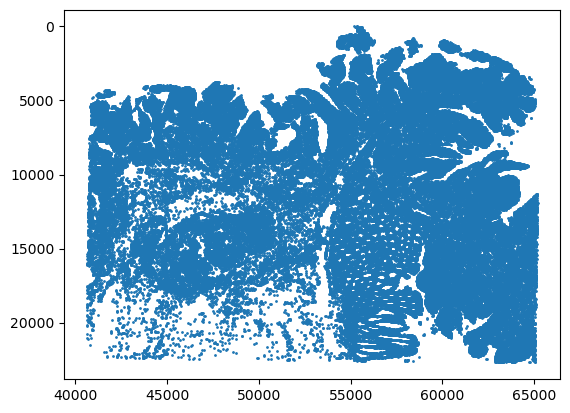

In [29]:
import matplotlib.pyplot as plt
plt.scatter(f_trans_adata.obsm['spatial'][:,0], f_trans_adata.obsm['spatial'][:,1], s=1)
plt.gca().invert_yaxis()
plt.show()

In [30]:
# 2. Store moran I result into var, aligned by gene name
print("2. Store moran I result into var, aligned by gene name")
moran_res = f_trans_adata.uns['moranI']

f_trans_adata.var['moranI'] = moran_res['I'].reindex(f_trans_adata.var_names)
f_trans_adata.var['moranI_pval_fdr'] = moran_res['pval_norm_fdr_bh'].reindex(f_trans_adata.var_names)

# 3. Define spatially variable genes by threshold
print("3. Define spatially variable genes by threshold")
f_trans_adata.var['spatially_variable'] = (
    (f_trans_adata.var['moranI_pval_fdr'] < 0.05) &
    (f_trans_adata.var['moranI'] > 0.1)   # adjust threshold based on your I distribution
)
print("3.:--------", f_trans_adata.var['spatially_variable'].sum(), "spatially variable genes")

# 4. Combine with HVGs
print("4. Combine with HVGs")
f_trans_adata.var['hvg_and_svg'] = (
    f_trans_adata.var['highly_variable'].fillna(False) &
    f_trans_adata.var['spatially_variable'].fillna(False)
)

f_trans_adata.var['gene_selection'] = 'none'
f_trans_adata.var.loc[f_trans_adata.var['highly_variable'].fillna(False), 'gene_selection'] = 'HVG'
f_trans_adata.var.loc[f_trans_adata.var['spatially_variable'].fillna(False), 'gene_selection'] = 'SVG'
f_trans_adata.var.loc[f_trans_adata.var['hvg_and_svg'], 'gene_selection'] = 'HVG_and_SVG'

print("4.:--------", f_trans_adata.var['gene_selection'].value_counts())


2. Store moran I result into var, aligned by gene name
3. Define spatially variable genes by threshold
3.:-------- 0 spatially variable genes
4. Combine with HVGs
4.:-------- gene_selection
none    16085
HVG      2000
Name: count, dtype: int64


In [35]:
moran_res = f_trans_adata.uns['moranI']

f_trans_adata.var['moranI'] = moran_res['I'].reindex(f_trans_adata.var_names)
f_trans_adata.var['moranI_pval_fdr'] = moran_res['pval_sim_fdr_bh'].reindex(f_trans_adata.var_names)

f_trans_adata.var['spatially_variable'] = (
    (f_trans_adata.var['moranI_pval_fdr'] < 0.05) &
    (f_trans_adata.var['moranI'] > 0.05)
)
print(f_trans_adata.var['spatially_variable'].sum())

209


In [32]:
print(f_trans_adata.uns['moranI'].describe())
print(f_trans_adata.uns['moranI'].sort_values('I', ascending=False).head(10))

                 I    pval_norm      var_norm    pval_z_sim     pval_sim  \
count  1993.000000  1993.000000  2.000000e+03  1.993000e+03  2000.000000   
mean      0.022286     0.233910  2.355081e-06  1.220147e-01     0.029658   
std       0.061770     0.231043  4.236224e-22  1.873962e-01     0.069907   
min      -0.001411     0.000000  2.355081e-06  0.000000e+00     0.009901   
25%      -0.000080     0.000000  2.355081e-06  0.000000e+00     0.009901   
50%       0.001171     0.206936  2.355081e-06  5.141285e-09     0.009901   
75%       0.015435     0.479431  2.355081e-06  3.184221e-01     0.009901   
max       0.660664     0.499966  2.355081e-06  4.990912e-01     0.495050   

            var_sim  pval_norm_fdr_bh  pval_z_sim_fdr_bh  pval_sim_fdr_bh  
count  1.993000e+03               0.0                0.0      2000.000000  
mean   1.250478e-06               NaN                NaN         0.032052  
std    2.216249e-06               NaN                NaN         0.070799  
min    7.25

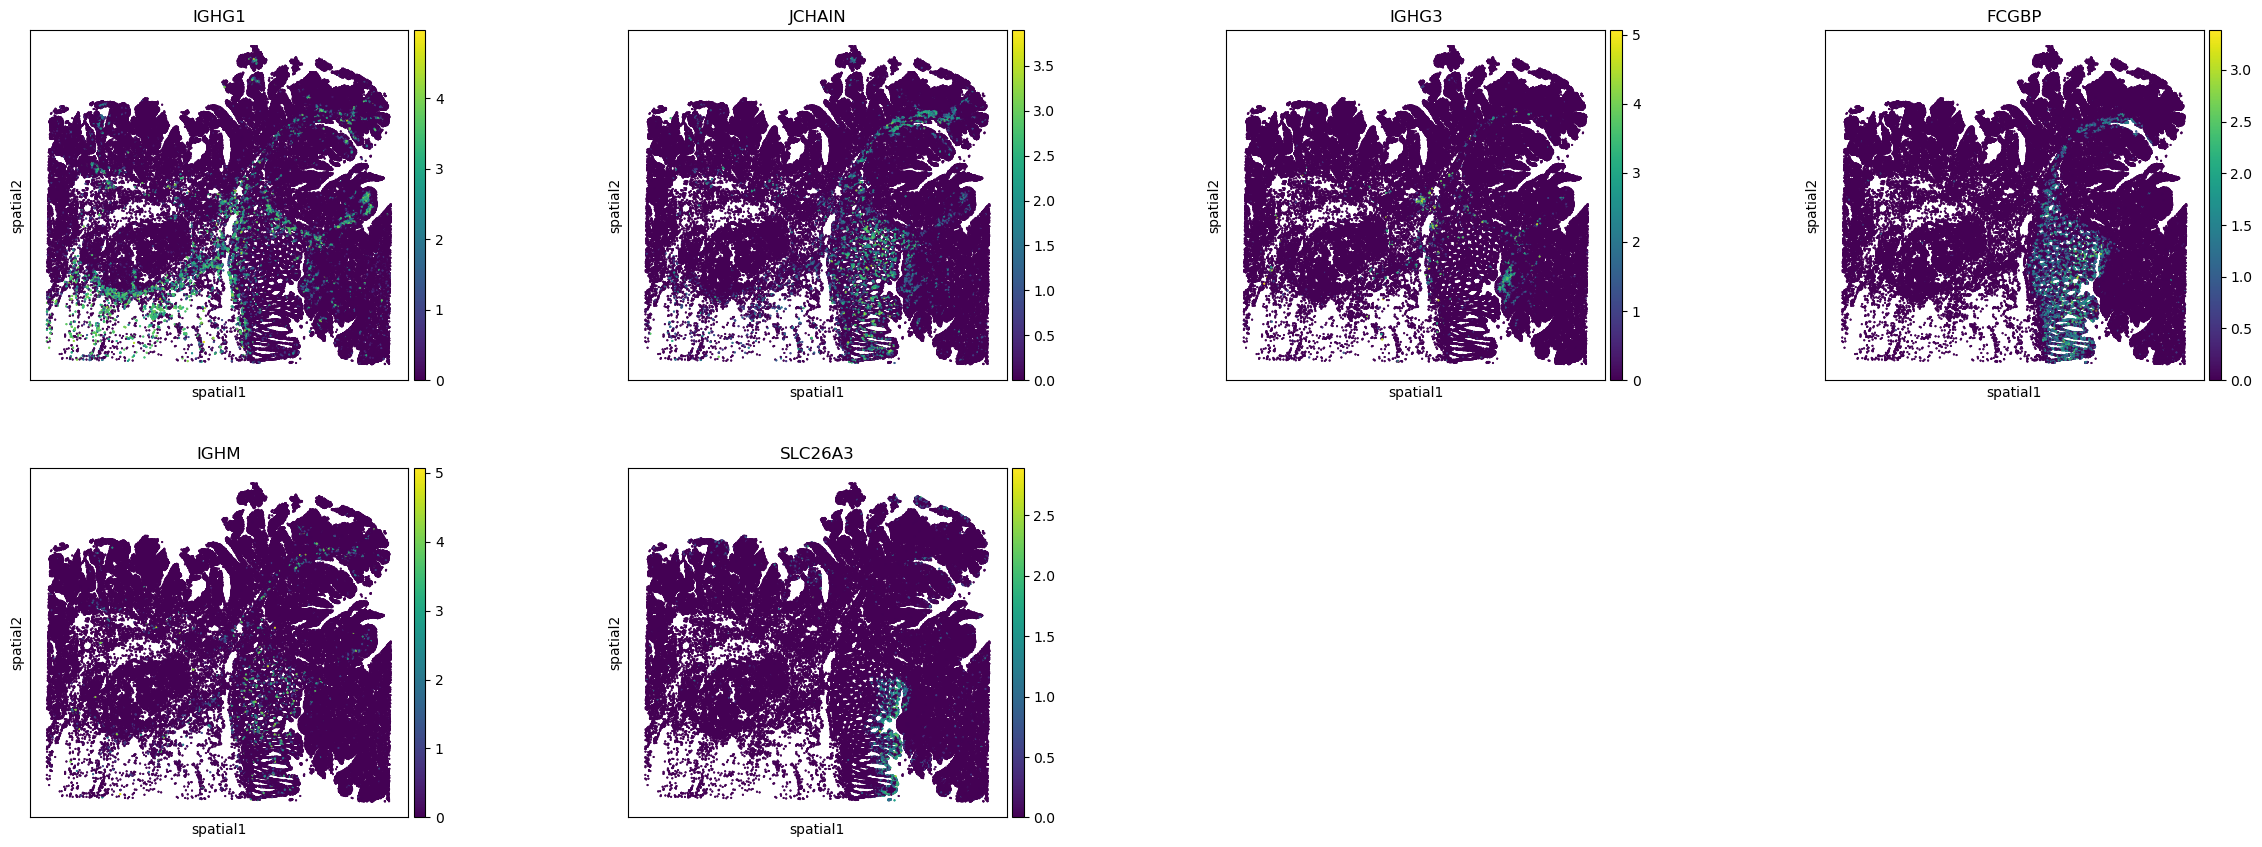

In [36]:
top_svgs = f_trans_adata.uns['moranI'].sort_values('I', ascending=False).head(6).index.tolist()

sq.pl.spatial_scatter(
    f_trans_adata,
    color=top_svgs,
    shape=None,       # no shape needed for centroid data
    size=1,
)

# Pairing the embeddings   
In this section we combine the modalities using autoencoders. 
The anndata object for transcriptomics stores a cell id for each cell (or aggregated bin), the patch id it has been assigned to, and the embedding for each cell.
The anndata object for histology contains a patch id for each patch as well as the corresponding histological embedding. 

The autoencoders require paired embeddings, hence we create a dict first that stores for each cell: the cell id, the embedding and the corresponding patch. 
Multiple cells can be assigned to one patch. 

Results from this cell:
- `X_rna`: numpy-array, stores one PCA embedding per cell (-> row)
- `X_hist`: numpy-array, stores all hist embeddings at the same position as the `X_rna` array

In [ ]:
# code: paring the embeddings
# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!
hist_pca_yes = False # tmp variable, see if histology autoencoder with or without PCA works better

if not xpca_trans:
    print ("NEEDS TO BE DONE")
    # perform pca on transcriptomics and histology?

patch_ids_hist = f_hist_adata.obs.index.values # get all patch_ids -> store in 1D array (i.e. ['Patch_1234', 'Patch_1235', ...])
if hist_pca_yes:
    hist_embeddings = f_hist_adata.obsm["X_pca"]  # get all patch embeddings (e.g.: [[0.xxxx, 1.yyyy, 0.zzzzz], [0.aaaa, 0.bbbb, 1.ccccc], [...], ...])
else:
    hist_embeddings= f_hist_adata.X

In the following cell, we 

In [8]:
patch_to_index = {pid: i for i, pid in enumerate(patch_ids_hist)}  # dict, maps each patch ID to its numeric row index in the histology array

rna_patch_ids = f_trans_adata.obs["Patch_ID"].values  # get assigned patch ID for each cell (can occur several times, as many cells per patch)
valid_mask = np.array([pid in patch_to_index for pid in rna_patch_ids]) # remove RNA cells whose patch does not exist in histology

X_rna = f_trans_adata.obsm["X_pca"][valid_mask] # store all PCA embeddings which are inside mask
rna_patch_ids = rna_patch_ids[valid_mask]  # get all patch ids from rna that exist in histology
cell_ids = f_trans_adata.obs.index.values[valid_mask] # all cell ids

hist_indices = np.array([patch_to_index[pid] for pid in rna_patch_ids])
X_hist = hist_embeddings[hist_indices]  # stores all hist embeddings at the same position as the X_rna obsm

# Sanity checks
assert X_rna.shape[0] == X_hist.shape[0]
assert X_rna.shape[1] == X_hist.shape[1]

# delete for RAM
# del patch_ids_hist, valid_mask, hist_embeddings
# gc.collect()

AssertionError: 

### Balancing spatial representation and standardising embeddings per modality
**Balancing spatial representation**: Goal: avoid overfitting. 
In the current approach, one patch can be assigned to many cells. 
To avoid overfitting from the loss function by patches with a large number of cells, we calculate the inverse frequency (`1.0/count`).
Now, cells from rare, sparsely populated patches get a higher weight, and cells from common, high-density patches get a lower weight. 
This ensures the model learns the spatial characteristics of every part of the tissue equally, not just the high-density centers.
This ties weights to specific cells before feeding them into the autoencoder.

**Standardising embeddings**: Goal: reduce modality gap. 
We apply z-score normalisation so that one modality does not dominate the other through higher PCA values or a greater variance.

In [5]:
# Create sample weights
unique_patches, patch_counts = np.unique(rna_patch_ids, return_counts=True)
patch_count_map = dict(zip(unique_patches, patch_counts))
sample_weights = np.array([1.0 / patch_count_map[pid] for pid in rna_patch_ids], dtype=np.float32)
sample_weights = sample_weights / sample_weights.mean()

# Stanadrdize embeddings per modality
eps = 1e-8
x_rna_original = X_rna
X_hist_original = X_hist
X_rna = (X_rna - X_rna.mean(axis=0)) / (X_rna.std(axis=0) + eps)
X_hist = (X_hist - X_hist.mean(axis=0)) / (X_hist.std(axis=0) + eps)

# Training with autoencoder and contrastive loss

### Create PyTorch Dataset

We use the numpy arrays from above (containing the histology and transcriptomics embeddings) to set up the PyTorch Dataset.
This class aligns the RNA and Histology features, ensuring that when the DataLoader delivers a batch to the model, the corresponding "RNA-Histology-Weight" combination per celll is always synchronized.


In [6]:
class PairDataset(Dataset):
    def __init__(self, X_rna, X_hist, cell_ids, patch_ids, sample_weights):
        self.X_rna = torch.tensor(X_rna, dtype=torch.float32) # transcript embeddings per cell
        self.X_hist = torch.tensor(X_hist, dtype=torch.float32)  # hist embeddings per cell
        self.cell_ids = np.asarray(cell_ids)  # cell id
        self.patch_ids = np.asarray(patch_ids)  # patch id assigned to cell
        self.weights = torch.tensor(sample_weights, dtype=torch.float32) # weight for each cell

    def __len__(self):
        return len(self.X_rna) # no. of cells (for epochs)

    def __getitem__(self, idx):
        return (
            self.X_rna[idx],
            self.X_hist[idx],
            self.cell_ids[idx],
            self.patch_ids[idx],
            self.weights[idx]
        )

Test and Validation Data Splitting

In [7]:
#Train/Validation split

from sklearn.model_selection import train_test_split

# Split UNIQUE patch IDs
unique_patch_ids = np.unique(rna_patch_ids)

train_patches, val_patches = train_test_split(
    unique_patch_ids,
    test_size=0.2,
    random_state=42
)

# Masks
train_mask = np.isin(rna_patch_ids, train_patches)
val_mask = np.isin(rna_patch_ids, val_patches)

# TRAIN
X_rna_train = X_rna[train_mask]
X_hist_train = X_hist[train_mask]
cell_ids_train = cell_ids[train_mask]
rna_patch_ids_train = rna_patch_ids[train_mask]
sample_weights_train = sample_weights[train_mask]

# VALIDATION
X_rna_val = X_rna[val_mask]
X_hist_val = X_hist[val_mask]
cell_ids_val = cell_ids[val_mask]
rna_patch_ids_val = rna_patch_ids[val_mask]
sample_weights_val = sample_weights[val_mask]

print(f"Train cells: {len(X_rna_train)}")
print(f"Validation cells: {len(X_rna_val)}")

print(f"Train patches: {len(np.unique(rna_patch_ids_train))}")
print(f"Validation patches: {len(np.unique(rna_patch_ids_val))}")

Train cells: 114892
Validation cells: 29373
Train patches: 6591
Validation patches: 1648


### DataLoader (mini-batching)

In [8]:
# dataset = PairDataset(X_rna, X_hist, cell_ids, rna_patch_ids, sample_weights)
# loader = DataLoader(dataset, batch_size=256, shuffle=True, drop_last=False)

train_dataset = PairDataset(
    X_rna_train,
    X_hist_train,
    cell_ids_train,
    rna_patch_ids_train,
    sample_weights_train
)

val_dataset = PairDataset(
    X_rna_val,
    X_hist_val,
    cell_ids_val,
    rna_patch_ids_val,
    sample_weights_val
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    drop_last=False
)

### Model architecture (symmetric)
Note: this should only be applied if **both embeddings have the same dimension**.  
(Currently assumed since we performed PCA with size=50 on both modalities)

**Encoder**: 
- Input layer: PCA-data (currently 50 dim)
- Hidden layer: Expand to 64 dim for complex non-linear patterns
- Bottleneck (`latent_dim`): compress to 64 dim into shared latent space

**Decoder**:
- smiliar.

In [9]:
input_dim = X_rna.shape[1] #currently 50, assumes X_rna.shape=x_hist.shape
latent_dim = 64
hidden_dim = 32

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )

    def forward(self, x):
        return self.net(x)

class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, z):
        return self.net(z)

### Loss function(s) - Alignment
**Option 1: Cosine similarity** (The "Alignment Check")  
- _How it works_: It normalizes the vectors to length 1 and calculates their dot product.  
- _The Math_: (a * b).sum() is the cosine similarity. 
1 - similarity turns this into a distance. 
If they point in the exact same direction (similarity=1), the loss is 0. 
If they point in opposite directions (similarity=-1), the loss is 2.  
- _Normalisation_: This forces each embedding to have length = 1, So they lie on a unit sphere. 
This removes magnitude differences, so that the model focuses only on direction (angle). Hence similarity:
    - 1 → same direction (perfect match)
    - 0 → orthogonal (unrelated)
    - -1 → opposite  
- _Loss_ (1 - cosine):
    - High similarity (1) → loss = 0 (perfect)
    - Low similarity (0) → loss = 1
    - Negative similarity → loss > 1
- _Usage_: It pulls paired samples (same cell, same patch) together, ensuring the RNA and Histology vectors for the same cell point in the same direction.


**Option 2: ntxent_loss** (The "Discriminator")  
- _How it works_: This is much smarter. It looks at the whole batch (batch_size x batch_size matrix of all potential pairings).  
- _The Math_: It uses CrossEntropyLoss to identify which pairs in the matrix are "positives" (the diagonal where $i=j$) versus "negatives" (everything else where $i \neq j$).
- _The Logic_: It doesn't just say "make these two close." 
It says, "Make these two close AND make sure this RNA vector is far from every other cell's histology in this batch."  
- _Why it's better_: It prevents the model from "cheating" by mapping every cell to the same spot. 
It forces the model to learn a unique "ID" for every cell-patch pair.

This is how the losses will be applied:  

input A → encoder → _a_ → decoder → output **A'**  
input B → encoder → _b_ → decoder → output **B'**  
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp;
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; ↑ 
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; 
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; ↑  
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; 
&nbsp; _cosine/ntxent loss_
&nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; **MSE**  

compare a with b   compare A' with A, B' with B  

In [10]:
def cosine_loss(a, b):
    a = F.normalize(a, dim=1)
    b = F.normalize(b, dim=1)
    return 1 - (a * b).sum(dim=1).mean()


def ntxent_loss(z1, z2, temperature=0.1):
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    
    logits = torch.matmul(z1, z2.T) / temperature
    labels = torch.arange(z1.size(0), device=z1.device)
    
    loss_1 = F.cross_entropy(logits, labels)
    loss_2 = F.cross_entropy(logits.T, labels)
    return (loss_1 + loss_2) / 2


# contrastive loss: InfoNCE NT-Xent as in paper
def ntxent_loss_old(z_rna, z_hist, temperature=0.05):
    batch_size = z_rna.shape[0]
    logits = torch.matmul(z_rna, z_hist.T) / temperature  # [B,B] similarity matrix
    labels = torch.arange(batch_size, device=z_rna.device)  # diagonal = positives
    return F.cross_entropy(logits, labels)

# alternatively (requires more dependencies)
# !pip install pytorch-metric-learning
# from pytorch_metric_learning import losses
# contrastive_loss = losses.NTXentLoss(temperature=0.1)
# align_loss = contrastive_loss(z_rna, z_hist)

### Instantiate models

Note: 
- MSE applied to `dec_rna` vs `original_rna` and `dec_hist` vs `original_hist`.  
- Alignment applied to `z_rna` vs `z_hist` 

In [11]:
enc_rna = Encoder(input_dim, hidden_dim, latent_dim)
enc_hist = Encoder(input_dim, hidden_dim, latent_dim)

dec_rna = Decoder(latent_dim, hidden_dim, input_dim)
dec_hist = Decoder(latent_dim, hidden_dim, input_dim)

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

enc_rna = enc_rna.to(device)
enc_hist = enc_hist.to(device)
dec_rna = dec_rna.to(device)
dec_hist = dec_hist.to(device)

In [13]:
# Set learning rate
opt = torch.optim.Adam(
    list(enc_rna.parameters()) +
    list(enc_hist.parameters()) +
    list(dec_rna.parameters()) +
    list(dec_hist.parameters()),
    lr=1e-3,
    weight_decay=1e-5 # tiny L2 regularisation to penalise large weights against overfitting
)

lambda_align = 1.0 # weight of alignment loss
lambda_cross = 1.0 # weight of cross modal loss
lambda_rec = 5.0 # double reconstruction loss

### Training 

In [14]:
num_epochs = 100
temperature = 0.5  # for NTXent

for epoch in range(num_epochs):

    # ================= TRAINING =================
    enc_rna.train()
    enc_hist.train()
    dec_rna.train()
    dec_hist.train()

    total_loss = 0.0
    total_rec = 0.0
    total_align = 0.0
    total_cross = 0.0

    for batch_idx, (x_rna, x_hist, cell_id, patch_id, b_weights) in enumerate(train_loader):

        x_rna = x_rna.to(device)
        x_hist = x_hist.to(device)
        b_weights = b_weights.to(device)

        # Forward
        z_rna = enc_rna(x_rna)
        z_hist = enc_hist(x_hist)

        z_rna_n = F.normalize(z_rna, dim=1)
        z_hist_n = F.normalize(z_hist, dim=1)

        # ---------------- Self reconstruction ----------------
        x_rna_rec = dec_rna(z_rna_n)
        x_hist_rec = dec_hist(z_hist_n)

        rec_rna = F.mse_loss(
            x_rna_rec,
            x_rna,
            reduction="none"
        ).mean(dim=1)

        rec_hist = F.mse_loss(
            x_hist_rec,
            x_hist,
            reduction="none"
        ).mean(dim=1)

        rec_loss = ((rec_rna + rec_hist) * b_weights).mean()

        # ---------------- Cross reconstruction ----------------
        x_rna_cross = dec_rna(z_hist_n)
        x_hist_cross = dec_hist(z_rna_n)

        cross_rna = F.mse_loss(
            x_rna_cross,
            x_rna,
            reduction="none"
        ).mean(dim=1)

        cross_hist = F.mse_loss(
            x_hist_cross,
            x_hist,
            reduction="none"
        ).mean(dim=1)

        cross_loss = ((cross_rna + cross_hist) * b_weights).mean()

        # ---------------- Alignment loss ----------------
        if loss_fct == "cosine":
            align_loss = cosine_loss(z_rna_n, z_hist_n)

        elif loss_fct == "ntxent":
            align_loss = ntxent_loss(
                z_rna_n,
                z_hist_n,
                temperature=temperature
            )

        else:
            raise ValueError(
                f"{loss_fct} is not implemented."
            )

        # ---------------- Total loss ----------------
        loss = (
            lambda_rec * rec_loss +
            lambda_align * align_loss +
            lambda_cross * cross_loss
        )

        # Backprop
        opt.zero_grad()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(enc_rna.parameters()) +
            list(enc_hist.parameters()) +
            list(dec_rna.parameters()) +
            list(dec_hist.parameters()),
            max_norm=5.0
        )

        opt.step()

        # Store metrics
        total_loss += loss.item()
        total_rec += rec_loss.item()
        total_align += align_loss.item()
        total_cross += cross_loss.item()

    # ================= TRAIN METRICS =================
    num_batches = len(train_loader)

    train_loss = total_loss / num_batches
    train_rec = total_rec / num_batches
    train_align = total_align / num_batches
    train_cross = total_cross / num_batches

    # ================= VALIDATION =================
    enc_rna.eval()
    enc_hist.eval()
    dec_rna.eval()
    dec_hist.eval()

    val_loss = 0.0
    val_rec = 0.0
    val_align = 0.0
    val_cross = 0.0

    with torch.no_grad():

        for x_rna, x_hist, _, _, b_weights in val_loader:

            x_rna = x_rna.to(device)
            x_hist = x_hist.to(device)
            b_weights = b_weights.to(device)

            # Forward
            z_rna = enc_rna(x_rna)
            z_hist = enc_hist(x_hist)

            z_rna_n = F.normalize(z_rna, dim=1)
            z_hist_n = F.normalize(z_hist, dim=1)

            # Self reconstruction
            x_rna_rec = dec_rna(z_rna_n)
            x_hist_rec = dec_hist(z_hist_n)

            rec_rna = F.mse_loss(
                x_rna_rec,
                x_rna,
                reduction="none"
            ).mean(dim=1)

            rec_hist = F.mse_loss(
                x_hist_rec,
                x_hist,
                reduction="none"
            ).mean(dim=1)

            rec_loss = ((rec_rna + rec_hist) * b_weights).mean()

            # Cross reconstruction
            x_rna_cross = dec_rna(z_hist_n)
            x_hist_cross = dec_hist(z_rna_n)

            cross_rna = F.mse_loss(
                x_rna_cross,
                x_rna,
                reduction="none"
            ).mean(dim=1)

            cross_hist = F.mse_loss(
                x_hist_cross,
                x_hist,
                reduction="none"
            ).mean(dim=1)

            cross_loss = ((cross_rna + cross_hist) * b_weights).mean()

            # Alignment
            if loss_fct == "cosine":
                align_loss = cosine_loss(z_rna_n, z_hist_n)

            elif loss_fct == "ntxent":
                align_loss = ntxent_loss(
                    z_rna_n,
                    z_hist_n,
                    temperature=temperature
                )

            # Total validation loss
            loss = (
                lambda_rec * rec_loss +
                lambda_align * align_loss +
                lambda_cross * cross_loss
            )

            val_loss += loss.item()
            val_rec += rec_loss.item()
            val_align += align_loss.item()
            val_cross += cross_loss.item()

    # Average validation metrics
    val_batches = len(val_loader)

    val_loss /= val_batches
    val_rec /= val_batches
    val_align /= val_batches
    val_cross /= val_batches

    # ================= PRINT =================
    if (epoch < 5) or ((epoch + 1) % 10 == 0):
        print(
            f"Epoch {epoch + 1:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"train_rec={train_rec:.4f} | "
            f"val_rec={val_rec:.4f} | "
            f"train_align={train_align:.4f} | "
            f"val_align={val_align:.4f}"
        )

# Final eval mode
enc_rna.eval()
enc_hist.eval()
dec_rna.eval()
dec_hist.eval()

Epoch 001 | train_loss=17.2139 | val_loss=14.7645 | train_rec=1.9510 | val_rec=1.4592 | train_align=5.0869 | val_align=5.2758
Epoch 002 | train_loss=14.1704 | val_loss=13.1936 | train_rec=1.3626 | val_rec=1.1432 | train_align=5.0477 | val_align=5.2819
Epoch 003 | train_loss=12.9323 | val_loss=12.2829 | train_rec=1.1124 | val_rec=0.9613 | train_align=5.0620 | val_align=5.2856
Epoch 004 | train_loss=12.1661 | val_loss=11.7020 | train_rec=0.9593 | val_rec=0.8459 | train_align=5.0625 | val_align=5.2798
Epoch 005 | train_loss=11.6136 | val_loss=11.2611 | train_rec=0.8487 | val_rec=0.7586 | train_align=5.0621 | val_align=5.2797
Epoch 010 | train_loss=10.5534 | val_loss=10.4766 | train_rec=0.6467 | val_rec=0.6087 | train_align=5.0313 | val_align=5.2615
Epoch 020 | train_loss=9.9947 | val_loss=10.0325 | train_rec=0.5411 | val_rec=0.5236 | train_align=5.0140 | val_align=5.2534
Epoch 030 | train_loss=9.8542 | val_loss=9.9087 | train_rec=0.5144 | val_rec=0.4987 | train_align=5.0007 | val_align=5.

Decoder(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=50, bias=True)
  )
)

### Extract final embeddings

In [13]:
with torch.no_grad():
    Z_rna = enc_rna(torch.tensor(X_rna, dtype=torch.float32, device=device))
    Z_hist = enc_hist(torch.tensor(X_hist, dtype=torch.float32, device=device))

    Z_rna = F.normalize(Z_rna, dim=1).cpu().numpy()
    Z_hist = F.normalize(Z_hist, dim=1).cpu().numpy()

# Evaluation and visualisation

This is to inspect the results of the autencoders, not of the graph yet.

In [16]:
print("Mean paired cosine:", cos_sim)

Mean paired cosine: 0.5909812


In [17]:
idx = np.random.permutation(len(Z_hist))
cos_shuffled = np.mean([np.dot(Z_rna[i], Z_hist[idx[i]]) for i in range(len(Z_rna))])
print("Shuffled cosine:", cos_shuffled)

Shuffled cosine: 0.052503336


In [15]:
# Compute paired cosine similarity
cos_sim = np.mean([np.dot(Z_rna[i], Z_hist[i]) for i in range(len(Z_rna))])
print(f"Mean paired cosine similarity: {cos_sim:.4f}")

# Should be >0.7 for good alignment
assert cos_sim > 0.5, "Poor alignment - retrain with higher lambda_align"

Mean paired cosine similarity: 0.5910


In [ ]:
# Print detailed diagnostics - next
cos_sims = [np.dot(Z_rna[i], Z_hist[i]) for i in range(len(Z_rna))]
cos_sim = np.mean(cos_sims)
cos_sim_std = np.std(cos_sims)

print(f"Mean paired cosine: {cos_sim:.4f} ± {cos_sim_std:.4f}")
print(f"Min paired cosine:  {min(cos_sims):.4f}")
print(f"Max paired cosine:  {max(cos_sims):.4f}")
print(f"5th percentile:      {np.percentile(cos_sims, 5):.4f}")

Mean paired cosine: 0.9547 ± 0.0470
Min paired cosine:  0.5311
Max paired cosine:  0.9956
5th percentile:      0.8528


In [ ]:
#import matplotlib.pyplot as plt
#import umap.umap_ as umap
#
## 1. UMAP overlay (should perfectly overlap)
#reducer = umap.UMAP(random_state=42)
#Z_umap_rna = reducer.fit_transform(Z_rna)
#Z_umap_hist = reducer.transform(Z_hist)  # Same manifold!
#
#plt.scatter(Z_umap_rna[:,0], Z_umap_rna[:,1], c='blue', alpha=0.5, label='RNA')
#plt.scatter(Z_umap_hist[:,0], Z_umap_hist[:,1], c='red', alpha=0.5, label='Histology')
#plt.legend()
#plt.title('Perfect Overlay = Success!')
#plt.show()

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-29 15:47:43.710496: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-04-29 15:47:43.732557: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/umap/umap_.p

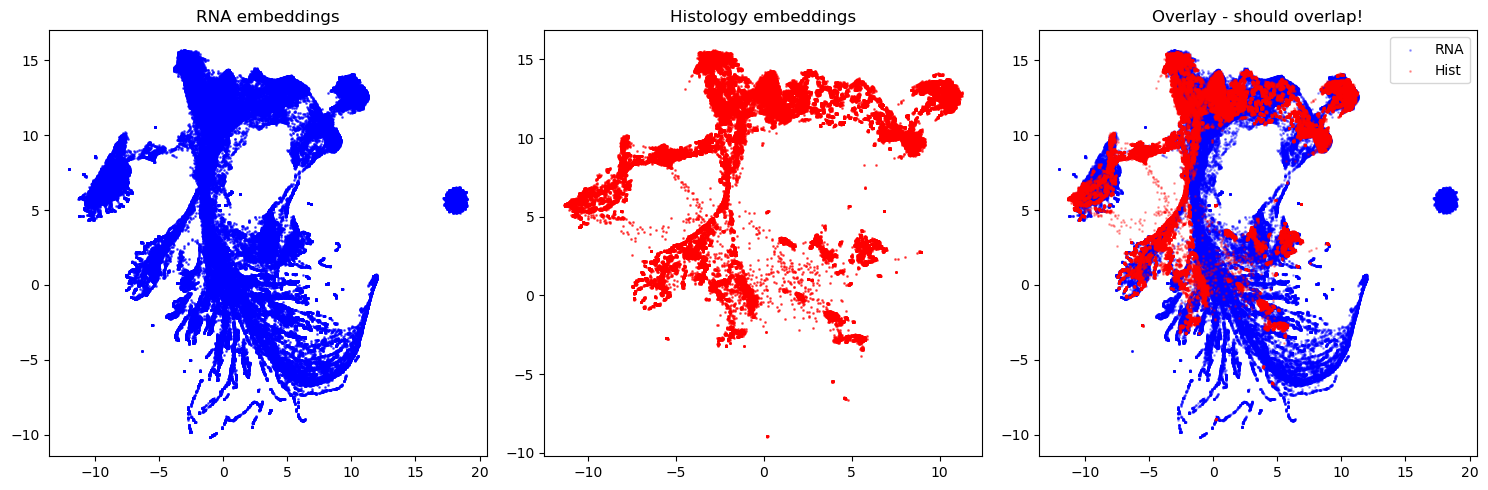

In [ ]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Fit UMAP on concatenated embeddings
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
Z_umap_rna = reducer.fit_transform(Z_rna)
Z_umap_hist = reducer.transform(Z_hist)  # Same UMAP!

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.scatter(Z_umap_rna[:, 0], Z_umap_rna[:, 1], c='blue', alpha=0.6, s=1)
plt.title('RNA embeddings')

plt.subplot(132) 
plt.scatter(Z_umap_hist[:, 0], Z_umap_hist[:, 1], c='red', alpha=0.6, s=1)
plt.title('Histology embeddings')

plt.subplot(133)
plt.scatter(Z_umap_rna[:, 0], Z_umap_rna[:, 1], c='blue', alpha=0.3, s=1, label='RNA')
plt.scatter(Z_umap_hist[:, 0], Z_umap_hist[:, 1], c='red', alpha=0.3, s=1, label='Hist')
plt.title('Overlay')
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
# reconstruction quality
# Reconstruct full dataset
with torch.no_grad():
    x_rna_rec = dec_rna(F.normalize(torch.tensor(Z_rna, device=device), dim=1))
    x_hist_rec = dec_hist(F.normalize(torch.tensor(Z_hist, device=device), dim=1))

# MSE on original PCA space
rna_mse = F.mse_loss(x_rna_rec.cpu(), torch.tensor(X_rna)).item()
hist_mse = F.mse_loss(x_hist_rec.cpu(), torch.tensor(X_hist)).item()
print(f"RNA reconstruction MSE: {rna_mse:.6f}")
print(f"Hist reconstruction MSE: {hist_mse:.6f}")
# Target: MSE < 0.1 (depends on your PCA variance)

RNA reconstruction MSE: 0.006112
Hist reconstruction MSE: 0.005095


In [ ]:
# Patch separation check
# Cosine similarity within vs between patches
from sklearn.metrics.pairwise import cosine_similarity

def patch_alignment(patch_ids, Z):
    # Ensure Z is normalized for cosine similarity = dot product
    Z_norm = Z / np.linalg.norm(Z, axis=1, keepdims=True)
    
    unique_patches = np.unique(patch_ids)
    n_patches = len(unique_patches)
    
    # NEW: True within-patch pairwise similarity (replaces broken diag)
    within_sims = []
    for pid in unique_patches:
        patch_mask = (patch_ids == pid)
        patch_cells = Z_norm[patch_mask]
        if len(patch_cells) > 1:
            sim_matrix = cosine_similarity(patch_cells)
            # Off-diagonal only (exclude self-similarity=1.0)
            upper_tri = sim_matrix[np.triu_indices_from(sim_matrix, k=1)]
            if len(upper_tri) > 0:
                within_sims.extend(upper_tri)
    within_patch = np.mean(within_sims) if within_sims else np.nan
    
    # Keep your centroid-based between-patch (unchanged)
    patch_means = np.array([Z_norm[patch_ids == pid].mean(axis=0) for pid in unique_patches])
    patch_means_norm = patch_means / np.linalg.norm(patch_means, axis=1, keepdims=True)
    sim_matrix = np.matmul(patch_means_norm, patch_means_norm.T)
    between_patch = (sim_matrix.sum() - np.diag(sim_matrix).sum()) / (n_patches * (n_patches - 1))
    
    return within_patch, between_patch

rna_within, rna_between = patch_alignment(rna_patch_ids, Z_rna)
hist_within, hist_between = patch_alignment(rna_patch_ids, Z_hist)

print(f"RNA:  within-patch={rna_within:.4f}, between-patch={rna_between:.4f}")
print(f"Hist: within-patch={hist_within:.4f}, between-patch={hist_between:.4f}")
# Good result: within > between by at least 0.2

RNA:  within-patch=1.0000, between-patch=0.1763
Hist: within-patch=1.0000, between-patch=0.1256


In [20]:
def check_patch_discrimination(patch_ids, Z):
    # Normalized embeddings
    Z_norm = Z / np.linalg.norm(Z, axis=1, keepdims=True)
    
    unique_pids = np.unique(patch_ids)
    within_sims = []
    between_sims = []
    
    for _ in range(1000):
        # Pick two random patches
        p1, p2 = np.random.choice(unique_pids, 2, replace=False)
        
        # Get cells for p1
        cells_p1 = Z_norm[patch_ids == p1]
        
        # Check if we have at least 2 cells for p1
        if len(cells_p1) < 2:
            continue # Skip patches with insufficient data
            
        # Pick two cells from p1
        c1, c2 = cells_p1[0], cells_p1[1]
        within_sims.append(np.dot(c1, c2))
        
        # Pick one from p1 and one from p2
        c3 = Z_norm[patch_ids == p2][0]
        between_sims.append(np.dot(c1, c3))
        
    return np.mean(within_sims), np.mean(between_sims)

w, b = check_patch_discrimination(rna_patch_ids, Z_rna)
print(f"Sampling check: Within={w:.4f}, Between={b:.4f}")

Sampling check: Within=0.6556, Between=0.1384


Integrated clustering silhouette: 0.1951


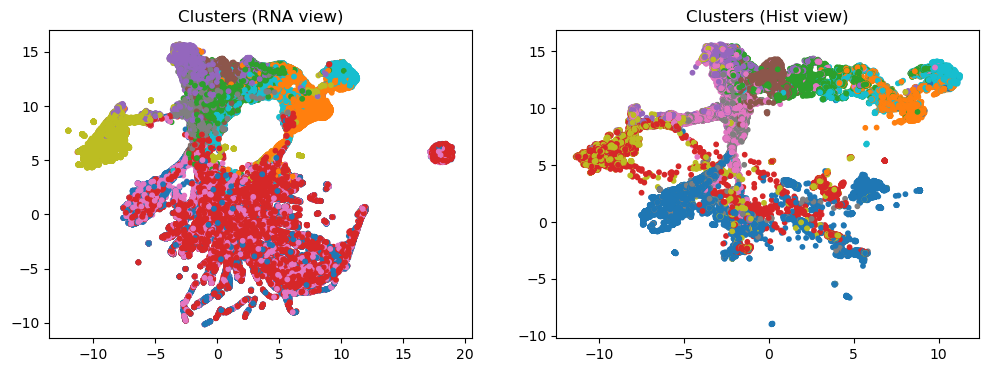

In [22]:
# integrated embedding clustering 
# Concatenate for integration
Z_integrated = np.concatenate([Z_rna, Z_hist], axis=1)

# Cluster and visualize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=10, random_state=42)
clusters = kmeans.fit_predict(Z_integrated)

sil_score = silhouette_score(Z_integrated, clusters)
print(f"Integrated clustering silhouette: {sil_score:.4f}")

# Plot clusters colored by patch or cell type
plt.figure(figsize=(12, 4))
plt.subplot(121)
plt.scatter(Z_umap_rna[:, 0], Z_umap_rna[:, 1], c=clusters, cmap='tab10', s=10)
plt.title('Clusters (RNA view)')

plt.subplot(122)
plt.scatter(Z_umap_hist[:, 0], Z_umap_hist[:, 1], c=clusters, cmap='tab10', s=10)
plt.title('Clusters (Hist view)')
plt.show()

Computing UMAP on a subset of 20000 cells...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Saved diagnostic plot to ../../data/CRC_P2/03_integration/autoencoders/002um/original_pca_umap_diagnostic.png


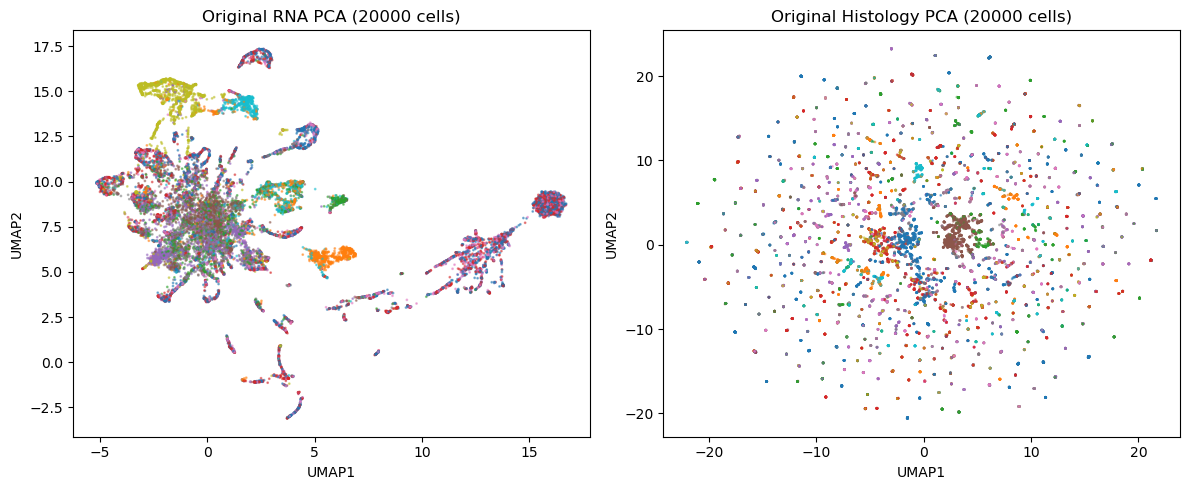

In [27]:
# --- START OF DIAGNOSTIC UMAP SECTION ---
import umap
import matplotlib.pyplot as plt
import numpy as np

# 1. Subsample for speed (essential for CPU runs)
# 5,000 cells is enough to see if the original PCA was messy
n_samples = min(20000, X_rna.shape[0])
idx = np.random.choice(X_rna.shape[0], n_samples, replace=False)

# 2. Initialize UMAP with parallelization
# n_jobs=-1 tells UMAP to use every core on your CPU
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=-1)

print(f"Computing UMAP on a subset of {n_samples} cells...")
umap_rna_orig = reducer.fit_transform(X_rna[idx])
umap_hist_orig = reducer.fit_transform(X_hist[idx])

# 3. Visualize the original embeddings
plt.figure(figsize=(12, 5))

# Original RNA PCA
plt.subplot(1, 2, 1)
plt.scatter(umap_rna_orig[:, 0], umap_rna_orig[:, 1], c=clusters[idx], cmap='tab10', s=1, alpha=0.5)
plt.title(f'Original RNA PCA ({n_samples} cells)')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')

# Original Histology PCA
plt.subplot(1, 2, 2)
plt.scatter(umap_hist_orig[:, 0], umap_hist_orig[:, 1], c=clusters[idx], cmap='tab10', s=1, alpha=0.5)
plt.title(f'Original Histology PCA ({n_samples} cells)')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')

plt.tight_layout()
plt.savefig(dir_output / "original_pca_umap_diagnostic.png")
print(f"Saved diagnostic plot to {dir_output}/original_pca_umap_diagnostic.png")
# --- END OF DIAGNOSTIC UMAP SECTION ---

# Tests


In [31]:
import pandas as pd
import anndata as ad
import numpy as np

# 1. Create the integrated embeddings for X (simple concatenation along the feature axis)
# Z_rna and Z_hist are both shape (n_cells, 64), so X_integrated will be (n_cells, 128)
X_integrated = np.concatenate((Z_rna, Z_hist), axis=1)

# 2. Create the obs DataFrame with cell_ids as the index and patch ids as a column
obs_df = pd.DataFrame(
    {"Patch_ID": rna_patch_ids}, 
    index=cell_ids.astype(str)  # Cast to string, which is standard practice for AnnData indices
)

# 3. Compile the obsm dictionary with the autoencoder outputs and original inputs
obsm_dict = {
    "Autoencoder_rna": Z_rna,          # Autoencoder latent RNA embeddings
    "Autoencoder_hist": Z_hist,        # Autoencoder latent histology embeddings
    "X_standardised_rna": X_rna,      # Original pre-autoencoder RNA embeddings (standardized)
    "X_standardised_hist": X_hist,     # Original pre-autoencoder Histology embeddings (standardized)
    'X_rna_raw': x_rna_original,
    'X_hist_raw': X_hist_original
}

# 4. Instantiate the new AnnData object
integrated_adata = ad.AnnData(
    X=X_integrated,
    obs=obs_df,
    obsm=obsm_dict
)

integrated_adata

AnnData object with n_obs × n_vars = 144265 × 128
    obs: 'Patch_ID'
    obsm: 'Autoencoder_rna', 'Autoencoder_hist', 'X_standardised_rna', 'X_standardised_hist', 'X_rna_raw', 'X_hist_raw'

In [33]:
####### UMAP ON RAW DATA
# 1. Compute neighbors using the raw RNA PCA stored in obsm
print("Getting neighbors")
sc.pp.neighbors(integrated_adata, use_rep='X_rna_raw', key_added='rna_raw_neighbors')
sc.pp.neighbors(integrated_adata, use_rep='X_hist_raw', key_added='hist_raw_neighbors')

print("running Leiden")
# 2. Run Leiden on the RNA-specific neighborhood graph
sc.tl.leiden(integrated_adata, resolution=0.2, neighbors_key='rna_raw_neighbors', key_added='leiden_rna_raw')
sc.tl.leiden(integrated_adata, resolution=0.2, neighbors_key='hist_raw_neighbors', key_added='leiden_hist_raw')

print("Running UMAP")
# 3. Run UMAP on the RNA-specific neighborhood graph
sc.tl.umap(integrated_adata, neighbors_key='rna_raw_neighbors')
integrated_adata.obsm['X_umap_rna_raw'] = integrated_adata.obsm['X_umap'].copy()
#sc.tl.umap(integrated_adata, neighbors_key='hist_raw_neighbors')
#integrated_adata.obsm['X_umap_hist_raw'] = integrated_adata.obsm['X_umap'].copy()

print("Plotting....")
# 4. Plot both UMAPs side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot RNA
sc.pl.embedding(
    integrated_adata, 
    basis='X_umap_rna_raw', 
    color='leiden_rna_raw', 
    title='UMAP: RNA Raw PCA', 
    ax=axes[0], 
    show=False
)

## Plot Histology
#sc.pl.embedding(
#    integrated_adata, 
#    basis='X_umap_hist_raw', 
#    color='leiden_hist_raw', 
#    title='UMAP: Histology Raw PCA', 
#    ax=axes[1], 
#    show=False
#)

plt.tight_layout()
plt.show()

Getting neighbors


KeyboardInterrupt: 

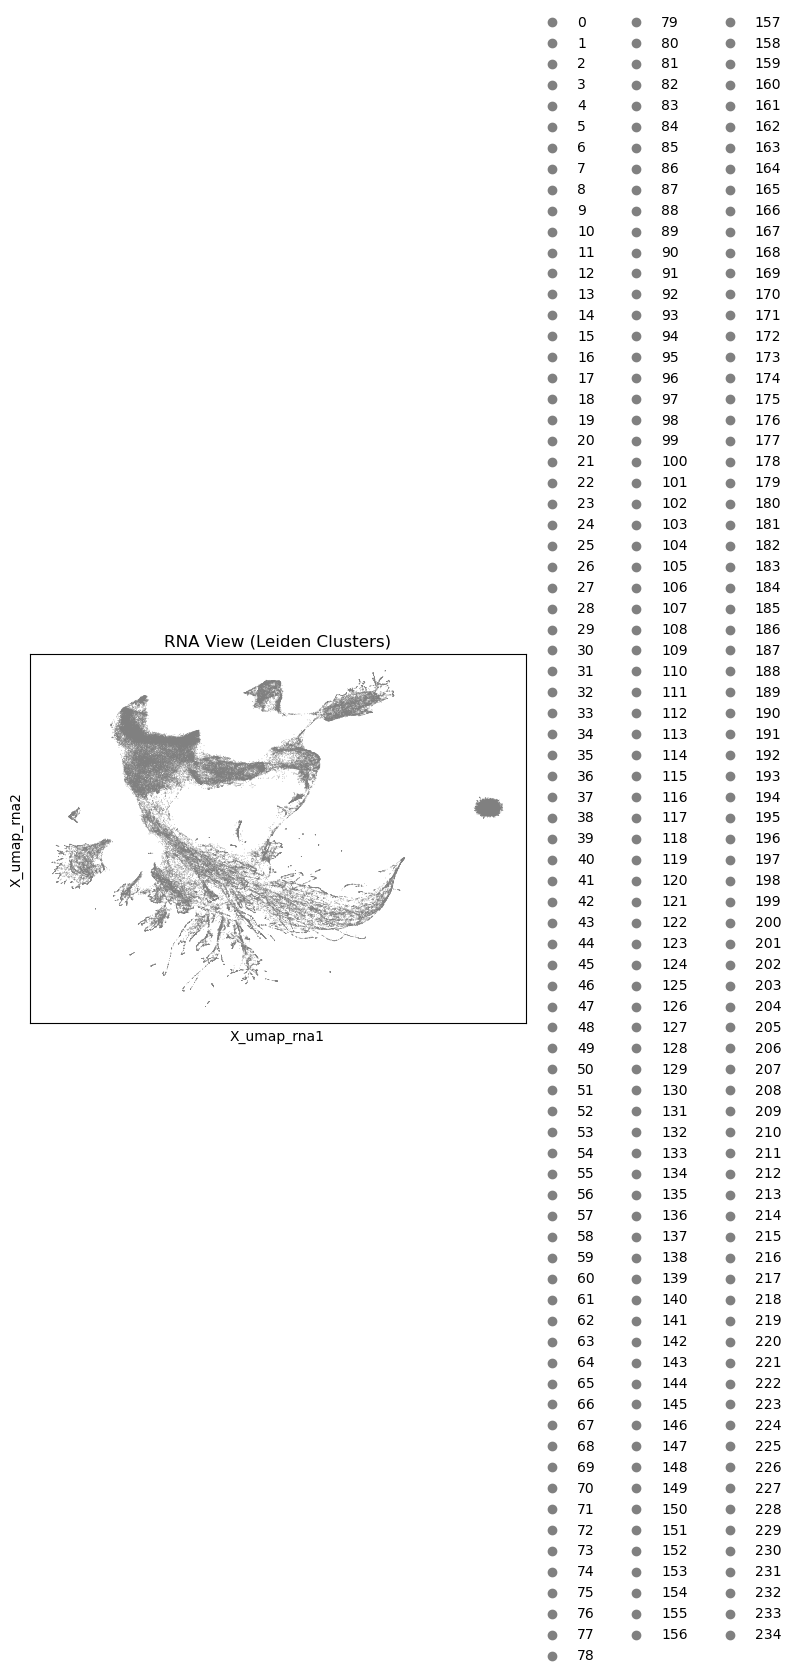

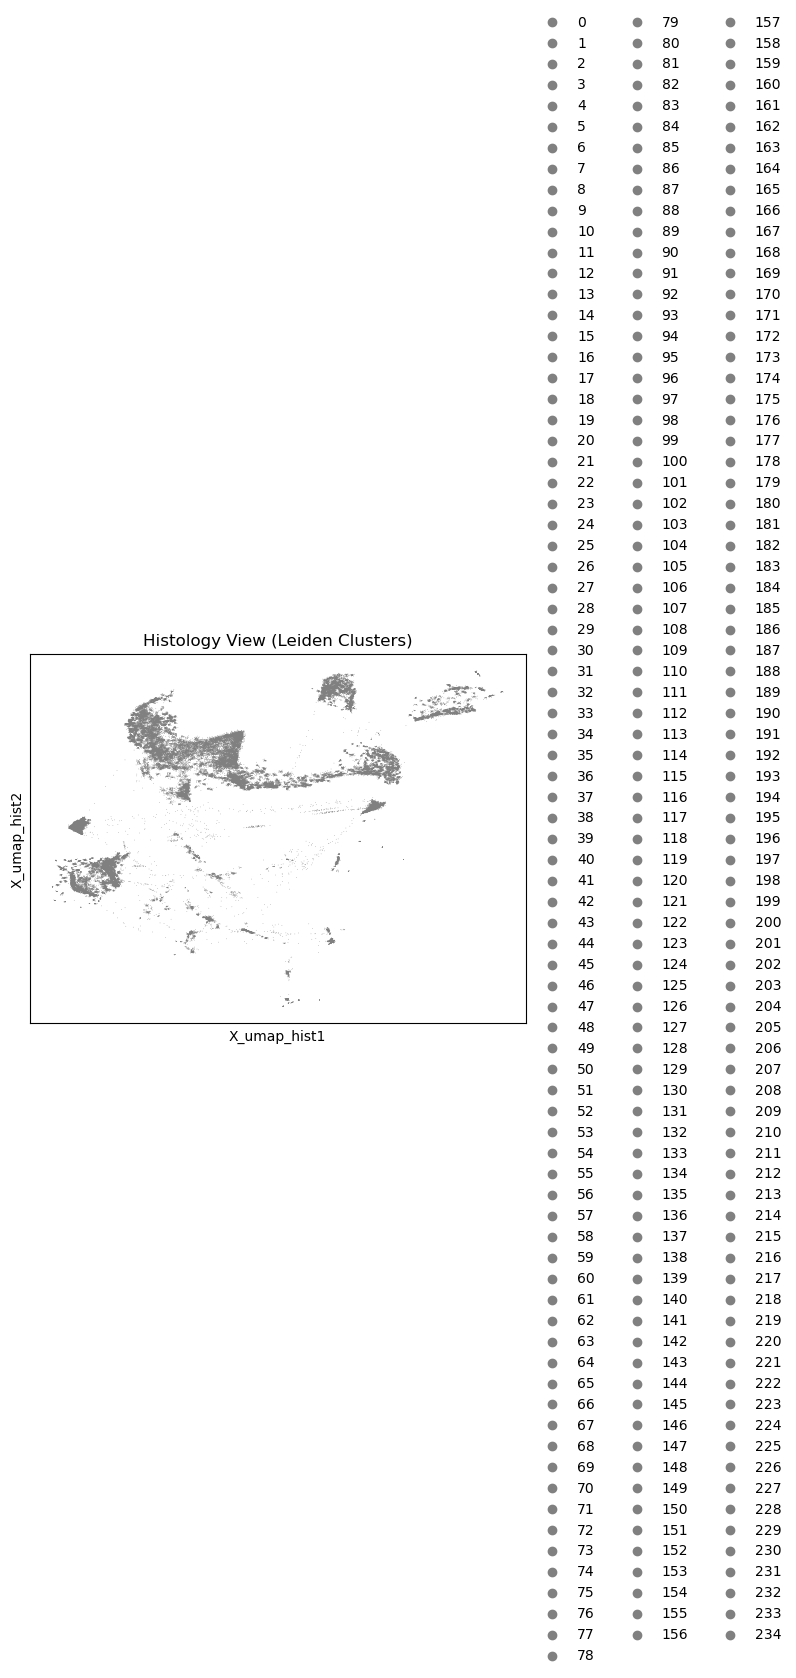

In [21]:
# Side-by-side comparison of the same clusters in both modalities
sc.pl.embedding(
    adata_integrated, 
    basis='X_umap_rna', 
    color=['leiden_clusters'], 
    title='RNA View (Leiden Clusters)'
)

sc.pl.embedding(
    adata_integrated, 
    basis='X_umap_hist', 
    color=['leiden_clusters'], 
    title='Histology View (Leiden Clusters)'
)

In [ ]:
# Create a subset of your original adata that only contains the integrated cells
adata_subset = f_trans_adata[trained_cell_ids].copy()

# Add the integrated embeddings and clusters
adata_subset.obsm['X_integrated'] = np.concatenate([Z_rna, Z_hist], axis=1)
sc.pp.neighbors(adata_subset, use_rep='X_integrated')
sc.tl.leiden(adata_subset, resolution=0.5, key_added='leiden_clusters')

# Add the UMAP coordinates you already calculated in Block 1
# Ensure Z_umap_rna/hist are also based on the same 20,000 cells
adata_subset.obsm['X_umap_rna'] = Z_umap_rna 
adata_subset.obsm['X_umap_hist'] = Z_umap_hist 

# Plot
sc.pl.embedding(adata_subset, basis='X_umap_rna', color='leiden_clusters', title='Leiden Clusters (RNA View)')
sc.pl.embedding(adata_subset, basis='X_umap_hist', color='leiden_clusters', title='Leiden Clusters (Hist View)')

In [ ]:
## Testing umap on original pca anndata embeddings
import scanpy as sc

# --- For Transcriptomics (Cells) ---
# 1. Use the existing PCA stored in .obsm['X_pca']
print("Transcriptomics")
print("Setting neighbors...")
sc.pp.neighbors(f_trans_adata, use_rep='X_pca', n_neighbors=15)

print("Computing UMAP")
# 2. Compute UMAP
sc.tl.umap(f_trans_adata)

print("Plotting")
# 3. Plot (colored by any metadata, e.g., 'Patch_ID' or 'id')
sc.pl.umap(f_trans_adata, color=['Patch_ID'], title='Original RNA UMAP (Scanpy)')

Histology
Setting neighbors...
computing umap...
Plotting...


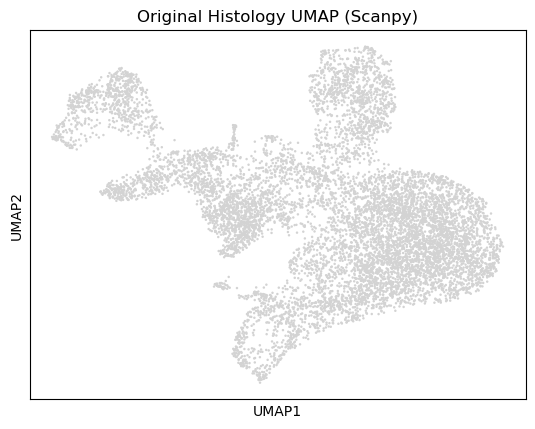

In [15]:
# --- For Histology (Patches) ---
print("Histology")
print("Setting neighbors...")
sc.pp.neighbors(f_hist_adata, use_rep='X_pca', n_neighbors=15)

print("computing umap...")
sc.tl.umap(f_hist_adata)

print("Plotting...")
# 3. Plot
sc.pl.umap(f_hist_adata, title='Original Histology UMAP (Scanpy)')

# Further Code

In [24]:
import umap
import matplotlib.pyplot as plt

# 1. Initialize UMAP
# n_neighbors: larger values focus on global structure, smaller on local
# min_dist: controls how tightly points are packed together
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)

# 2. Fit and transform original PCA embeddings
print("Computing UMAP for original RNA PCA...")
umap_rna_orig = reducer.fit_transform(X_rna)

print("Computing UMAP for original Histology PCA...")
umap_hist_orig = reducer.fit_transform(X_hist)

# 3. Visualize the original embeddings
# We use the same clusters you calculated for the integrated space 
# to see if they were already 'messy' in the original data
plt.figure(figsize=(12, 5))

# Original RNA PCA
plt.subplot(1, 2, 1)
plt.scatter(umap_rna_orig[:, 0], umap_rna_orig[:, 1], c=clusters, cmap='tab10', s=1, alpha=0.5)
plt.title('Original RNA PCA (UMAP Projection)')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')

# Original Histology PCA
plt.subplot(1, 2, 2)
plt.scatter(umap_hist_orig[:, 0], umap_hist_orig[:, 1], c=clusters, cmap='tab10', s=1, alpha=0.5)
plt.title('Original Histology PCA (UMAP Projection)')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')

plt.tight_layout()
plt.savefig("original_pca_umap.png")
print("Saved UMAP visualization to original_pca_umap.png")

Computing UMAP for original RNA PCA...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Computing UMAP for original Histology PCA...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


KeyboardInterrupt: 

In [ ]:
#6. Quick Dashboard (One Function)
def validate_integration(Z_rna, Z_hist, X_rna, X_hist, rna_patch_ids, dec_rna, dec_hist):
    print("=== INTEGRATION VALIDATION ===")
    
    # 1. Alignment
    cos_sim = np.mean([np.dot(a,b) for a,b in zip(Z_rna, Z_hist)])
    print(f"✓ Paired cosine similarity: {cos_sim:.4f}")
    
    # 2. Clustering quality
    Z_int = np.concatenate([Z_rna, Z_hist], axis=1)
    sil = silhouette_score(Z_int, KMeans(10).fit_predict(Z_int))
    print(f"✓ Integrated silhouette score: {sil:.4f}")
    
    # 3. Reconstruction
    with torch.no_grad():
        rec_rna = dec_rna(F.normalize(torch.tensor(Z_rna[:1000], device=device), dim=1))
        mse_rna = F.mse_loss(rec_rna.cpu(), torch.tensor(X_rna[:1000])).item()
    print(f"✓ RNA reconstruction MSE: {mse_rna:.4f}")
    
    print("\n🎉 Looks good!" if cos_sim > 0.6 and sil > 0.3 else "\n⚠️  Check alignment/retrain")

validate_integration(Z_rna, Z_hist, X_rna, X_hist, rna_patch_ids, dec_rna, dec_hist)

=== INTEGRATION VALIDATION ===
✓ Paired cosine similarity: 0.9547


KeyboardInterrupt: 

In [ ]:
# 2. Patch separation preserved?
rna_within, rna_between = patch_alignment(rna_patch_ids, Z_rna)
print(f"Within-patch sim: {rna_within:.4f}, Between-patch: {rna_between:.4f}")
# Should see within > between by ~0.1-0.2

Within-patch sim: 1.0000, Between-patch: 0.9598
